In [6]:
from meanres2 import mean_res

verbose = True
mr = mean_res()
wbdf = mr.read_WB_models('Models/Combined_mod.xyz',verbose=verbose)
mr.WB2Anemone(wbdf,verbose=verbose)

Reading Models/Combined_mod.xyz
  EPSG: 32636
  30 layers
  6522 sites
  Done.
Converting to Anemone data frame
  Performing melt 0
  Performing melt 1
  Performing melt 2
  Merging melted dataframes
  Done.


0

In [29]:
wbdf

,X,Y,RECORD,ELEVATION,RESDATA,RHO_1,RHO_2,RHO_3,RHO_4,RHO_5,...,THK_24,THK_25,THK_26,THK_27,THK_28,THK_29,THK_30,DOI_STANDARD,latitude,longitude
0,707713.80,407247.50,1,599.0,0.6879,26.040,30.520,41.58,37.900,37.970,...,26.48,30.53,35.20,40.59,46.81,53.97,199.997,167.450,3.682475,34.870176
1,709207.60,408312.60,2,621.5,0.8487,17.510,21.280,19.42,16.600,11.560,...,26.48,30.53,35.20,40.59,46.81,53.97,199.997,211.599,3.692077,34.883641
2,709263.70,408493.60,3,629.0,0.8513,26.090,21.350,14.14,7.806,4.704,...,26.48,30.53,35.20,40.59,46.81,53.97,199.997,179.574,3.693712,34.884149
3,709018.30,407290.00,4,629.0,0.8330,31.740,28.000,21.47,14.090,7.594,...,26.48,30.53,35.20,40.59,46.81,53.97,199.997,127.879,3.682834,34.881918
4,707653.80,409481.00,5,607.0,0.9926,6.865,8.294,11.76,17.760,25.690,...,26.48,30.53,35.20,40.59,46.81,53.97,199.997,99.458,3.702671,34.869678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6517,710024.61,410021.83,6518,629.0,0.6308,24.680,19.540,17.03,14.050,10.680,...,19.52,22.21,25.27,28.76,32.72,37.24,149.999,83.782,3.707516,34.891027
6518,709967.93,410024.44,6519,629.0,0.5896,23.570,17.550,16.11,14.070,10.990,...,19.52,22.21,25.27,28.76,32.72,37.24,149.999,82.439,3.707541,34.890517
6519,709869.02,410037.40,6520,626.4,0.8203,21.890,20.870,19.09,16.270,14.200,...,19.52,22.21,25.27,28.76,32.72,37.24,149.999,83.127,3.707660,34.889627
6520,709801.46,410074.57,6521,625.7,0.9594,17.590,17.230,14.06,10.800,9.484,...,19.52,22.21,25.27,28.76,32.72,37.24,149.999,83.764,3.707997,34.889020


In [30]:
thick2a,thick2b = wbdf['THK_2'].unique()
wbdf1 = wbdf[wbdf['THK_2'] == thick2a]
wbdf2 = wbdf[wbdf['THK_2'] == thick2b]

In [34]:
mr.WB2Anemone(wbdf2,verbose=verbose)
mr.data

Converting to Anemone data frame


c:\Users\au646858\OneDrive - Aarhus Universitet\Documents\_repositories\sea-anemone\app\meanres2.py:117: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wbdf[['latitude','longitude']] = latlon


  Performing melt 0
  Performing melt 1
  Performing melt 2
  Merging melted dataframes
  Done.


,site_id,latitude,longitude,elevation,easting,northing,doi,layer,resistivity,top_depth,bottom_depth,center_depth
0,6,3.685089,34.880654,613.0,708877.30,407539.10,130.974,0,34.76,0.000,1.000,0.5000
1,7,3.689822,34.870313,606.0,707727.30,408060.10,212.185,0,45.43,0.000,1.000,0.5000
2,8,3.693043,34.868262,610.0,707498.70,408415.90,162.410,0,31.80,0.000,1.000,0.5000
3,9,3.685553,34.870203,617.0,707716.10,407587.90,195.195,0,30.58,0.000,1.000,0.5000
4,10,3.693288,34.890196,626.8,709935.57,408448.13,63.338,0,12.39,0.000,1.000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...
195505,6518,3.707516,34.891027,629.0,710024.61,410021.83,83.782,29,58.99,299.998,449.997,374.9975
195506,6519,3.707541,34.890517,629.0,709967.93,410024.44,82.439,29,58.94,299.998,449.997,374.9975
195507,6520,3.707660,34.889627,626.4,709869.02,410037.40,83.127,29,59.20,299.998,449.997,374.9975
195508,6521,3.707997,34.889020,625.7,709801.46,410074.57,83.764,29,59.27,299.998,449.997,374.9975


In [35]:
d_top = mr.data['top_depth'].unique()
d_bot = mr.data['bottom_depth'].unique()
res_grid = mr.data.pivot_table('resistivity', 'site_id', 'center_depth')

In [36]:
res_grid

center_depth,0.5000,1.5690,2.7855,4.1695,5.7445,7.5370,9.5765,11.8970,14.5375,17.5425,...,95.4330,109.5930,125.7030,144.0380,164.9030,188.6430,215.6580,246.3980,281.3780,374.9975
site_id,,,,,,,,,,,,,,,,,,,,,
6,34.760,31.30,25.13,17.870,11.620,8.176,7.510,8.382,8.852,7.964,...,1.869,3.574,6.263,8.607,9.771,9.823,9.249,8.545,8.052,7.883
7,45.430,40.34,35.94,30.190,23.160,21.080,18.120,14.360,11.820,11.630,...,8.400,8.097,7.797,7.470,7.536,8.157,8.961,9.471,9.487,9.083
8,31.800,28.85,28.52,27.060,22.530,12.190,4.801,4.298,5.183,3.828,...,4.250,2.741,3.796,5.120,6.111,7.092,8.200,9.194,9.753,9.844
9,30.580,34.16,41.47,51.320,59.470,58.190,63.570,74.090,73.380,80.720,...,7.432,6.563,4.583,3.078,3.476,5.617,8.329,10.340,11.030,10.580
10,12.390,16.24,16.02,13.470,11.380,8.085,6.104,3.283,6.132,11.460,...,25.530,36.800,46.280,52.830,56.200,56.860,55.660,53.610,51.480,49.590
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6518,24.680,19.54,17.03,14.050,10.680,7.418,5.102,3.964,4.668,7.459,...,11.030,16.300,22.640,29.510,36.220,42.290,47.170,50.950,54.260,58.990
6519,23.570,17.55,16.11,14.070,10.990,8.060,6.315,6.180,7.712,9.961,...,10.720,15.900,22.260,29.160,35.920,42.030,47.030,50.860,54.180,58.940
6520,21.890,20.87,19.09,16.270,14.200,14.180,15.710,17.260,16.850,12.960,...,11.030,16.200,22.520,29.360,36.060,42.110,47.120,50.930,54.300,59.200


In [60]:
import numpy as np

def rediscretize(z_old, z_new):
    """this function rediscretizes values onto a new grid. if an interval on the new discretization spans several layers, the resulting average will be thickness averaged."""
    if type(z_old) is tuple:
        z_old1,z_old2 = z_old
    elif isinstance(z_old, np.ndarray):
        z_old1 = np.insert(z_old, 0,0)[:-1]
        z_old2 = z_old*1

    if type(z_new) is tuple:
        z_new1,z_new2 = z_new
    elif isinstance(z_new, np.ndarray):
        z_new1 = np.insert(z_new, 0,0)[:-1]
        z_new2 = z_new*1

    zo1,zn1 = np.meshgrid(z_old1, z_new1, indexing='ij')
    zo2,zn2 = np.meshgrid(z_old2, z_new2, indexing='ij')

    ov1 = np.max(np.stack([zo1,zn1]), axis=0)
    ov2 = np.min(np.stack([zo2,zn2]), axis=0)
    ov = ov2-ov1
    ov[ov<0] = 0

    if z_new2[-1] > z_old2[-1]:
        ov[-1, -1] = 1.
    
    ov /= ov.sum(0, keepdims=True)
    
    return ov.T

In [77]:
import matplotlib.pyplot as plt

z_old = np.unique(np.concatenate((d_top[1:],d_bot)))
z_old.sort()

#z_new = np.array([5., 10., 15., 20., 25., 30., 40., 50., 60., 70., 80., 100., 110., 120., 130., 140., 150., 175., 200., 225. , 250., 300., 350., 400., 450., 500.])
z_new = np.array([25., 50.])

redisc_mat = rediscretize(z_old, z_new)[1:]

<Figure size 640x480 with 0 Axes>

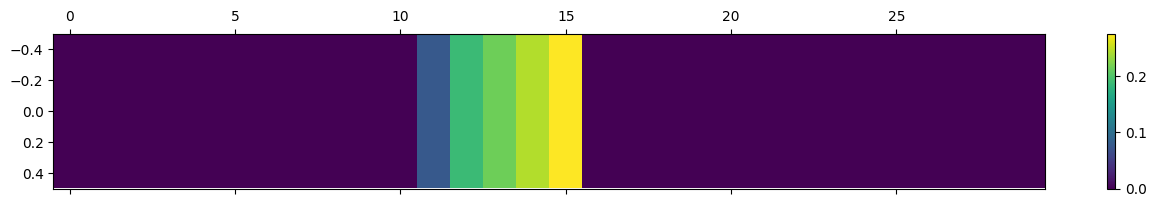

In [78]:
plt.figure()
pcm = plt.matshow(redisc_mat, aspect='auto')
plt.colorbar(pcm)

In [79]:
mean_res = redisc_mat @ res_grid.values.T

In [80]:
mean_res.shape

(1, 6517)